### Часть 1.

In [23]:
import json
import time
import re
from pathlib import Path

import pandas as pd
import requests

In [24]:
HEADERS = {
    "User-Agent": "student_of_miniDH-scraping-course (https://github.com/mashunik)"
}

In [26]:
def get_json(url: str, attempts: int = 3, headers: dict = HEADERS):
  """Отправляет GET-запрос и возвращает JSON; при временных сбоях повторяет запрос."""

  for attempt in range(1, attempts + 1):
    try:
      response = requests.get(url, headers=headers, timeout=10)

    except (requests.exceptions.Timeout, requests.exceptions.ConnectionError):
      print(f"Попытка {attempt}: нет ответа от сервера")
      time.sleep(5)
      continue

    if response.status_code in (429, 503):
      print(f"Попытка {attempt}: код {response.status_code}, сервер просит подождать")
      time.sleep(5)
      continue

    response.raise_for_status()
    return response.json()

  raise RuntimeError(f"Не удалось получить ответ за {attempts} попытки: {url}")

In [27]:
BASE_URL = "https://poetrydb.org"

authors = ["Emily Dickinson", "Christina Rossetti"]

all_poems = []

for author in authors:
  url = f"{BASE_URL}/author/{author}:abs"

  poems = get_json(url)

  if not isinstance(poems, list) or not poems:
      raise ValueError(f"Не удалось получить стихотворения: {author}")

  all_poems.extend(poems)

  print(f"{author}: получено {len(poems)} стихотворений")

  time.sleep(1)

print(f"Всего получено: {len(all_poems)} стихотворений")
print(all_poems[0].keys())

Emily Dickinson: получено 446 стихотворений
Christina Rossetti: получено 13 стихотворений
Всего получено: 459 стихотворений
dict_keys(['title', 'author', 'lines', 'linecount', 'source'])


In [28]:
fields = ["author", "title", "text", "linecount"]

for field in fields:
  missing = df[field].isna().sum()

  print(f"{field}: {missing} пропусков")

author: 0 пропусков
title: 0 пропусков
text: 0 пропусков
linecount: 0 пропусков


In [29]:
data = []

for poem in all_poems:
  text = "\n".join(poem["lines"])

  data.append({
    "author": poem["author"],
    "title": poem["title"],
    "linecount": int(poem["linecount"]),
    "text": text,
    "dashes": len(re.findall(r"--+|[—–]", text)),
    "questions": text.count("?"),
    "exclamations": text.count("!")
  })

df = pd.DataFrame(data)
df.head()

,author,title,linecount,text,dashes,questions,exclamations
0,Emily Dickinson,I'm nobody! Who are you?,8,"I'm nobody! Who are you?\nAre you nobody, too...",1,2,4
1,Emily Dickinson,I heard a fly buzz when I died,16,I heard a fly buzz when I died;\nThe stillness...,1,0,0
2,Emily Dickinson,Success is counted sweetest,12,Success is counted sweetest\nBy those who ne'e...,0,0,1
3,Emily Dickinson,Our share of night to bear,8,"Our share of night to bear,\nOur share of morn...",1,0,1
4,Emily Dickinson,"Soul, wilt thou toss again?",8,"Soul, wilt thou toss again?\nBy just such a ha...",0,1,0


In [30]:
df.to_csv("data.csv", index=False, encoding="utf-8")

print(f"Сохранено {len(df)} стихотворений")

Сохранено 459 стихотворений


In [65]:
summary = df.groupby("author").agg(
  poems=("title", "count"),
  total_lines=("linecount", "sum"),
  dashes=("dashes", "sum"),
  questions=("questions", "sum"),
  exclamations=("exclamations", "sum")
)

for mark in ["dashes", "questions", "exclamations"]:
  summary[mark + "_per_100_lines"] = (summary[mark] / summary["total_lines"] * 100).round(2)

summary

,poems,total_lines,dashes,questions,exclamations,dashes_per_100_lines,questions_per_100_lines,exclamations_per_100_lines
author,,,,,,,,
Christina Rossetti,13,538,14,26,11,2.60,4.83,2.04
Emily Dickinson,446,5440,349,150,406,6.42,2.76,7.46


In [66]:
# Посмотрим только для Дикинсон, так как у Россети слишком мало текстов
dickinson = df[df["author"] == "Emily Dickinson"].copy()

dickinson["length_group"] = pd.cut(
  dickinson["linecount"],
  bins=[0, 12, 24, float("inf")],
  labels=["Короткие", "Средние", "Длинные"]
)

length_summary = dickinson.groupby("length_group", observed=True).agg(
  poems=("title", "count"),
  total_lines=("linecount", "sum"),
  dashes=("dashes", "sum"),
  questions=("questions", "sum"),
  exclamations=("exclamations", "sum")
)

for mark in ["dashes", "questions", "exclamations"]:
  length_summary[mark + "_per_100_lines"] = (length_summary[mark] / length_summary["total_lines"] * 100).round(2)

length_summary

,poems,total_lines,dashes,questions,exclamations,dashes_per_100_lines,questions_per_100_lines,exclamations_per_100_lines
length_group,,,,,,,,
Короткие,299,2541,147,86,204,5.79,3.38,8.03
Средние,130,2361,160,42,168,6.78,1.78,7.12
Длинные,17,538,42,22,34,7.81,4.09,6.32


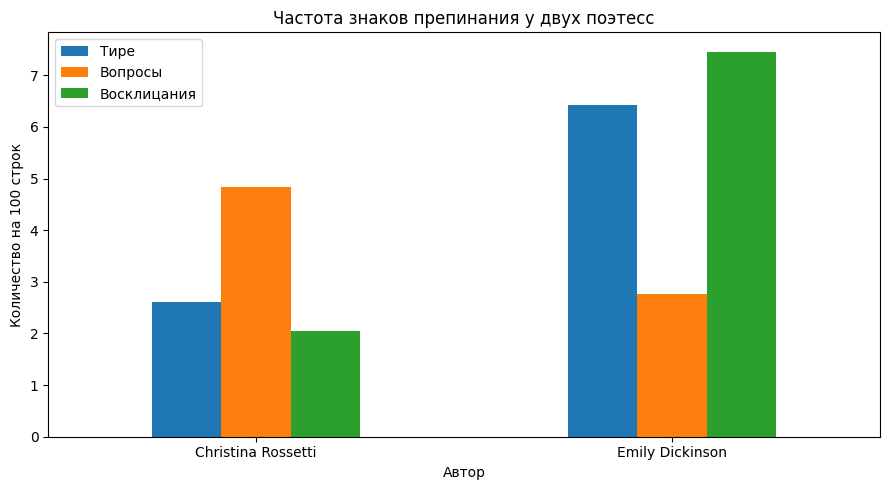

In [33]:
'''График в качестве бонуса'''
import matplotlib.pyplot as plt

columns = [
  "dashes_per_100_lines",
  "questions_per_100_lines",
  "exclamations_per_100_lines"
]

summary[columns].plot(kind="bar", figsize=(9, 5))

plt.title("Частота знаков препинания у двух поэтесс")
plt.ylabel("Количество на 100 строк")
plt.xlabel("Автор")
plt.xticks(rotation=0)
plt.legend(["Тире", "Вопросы", "Восклицания"])
plt.tight_layout()
plt.show()

### Часть 2.

In [45]:
def new_get_json(url: str, params: dict, attempts: int = 3, headers: dict = HEADERS):
    for attempt in range(1, attempts + 1):
      try:
        response = requests.get(url, params=params, headers=headers, timeout=60)

      except (requests.exceptions.Timeout, requests.exceptions.ConnectionError):
          print(f"Попытка {attempt}: нет ответа от сервера")
          time.sleep(5)
          continue

      if response.status_code == 429:
          retry_after = response.headers.get("Retry-After")
          wait = int(retry_after) if retry_after and retry_after.isdigit() else 60 * attempt

          print(f"Превышен лимит запросов. Повтор через {wait} секунд")
          time.sleep(wait)
          continue

      if response.status_code in (500, 502, 503, 504):
          print(f"Попытка {attempt}: ошибка {response.status_code}")
          time.sleep(5)
          continue

      response.raise_for_status()
      return response.json()

    raise RuntimeError(f"Не удалось получить ответ за {attempts} попытки: {url}")

In [56]:
API_URL = "https://datasets-server.huggingface.co/search"
DATASET = "yoonholee/poetry-greats-public-domain"

def search_poetry_greats(author: str, max_records: int = 10000, limit: int = 25, max_requests: int = 25) -> list[dict]:
    records = []
    offset = 0

    for _ in range(max_requests):
        params = {
            "dataset": DATASET,
            "config": "default",
            "split": "train",
            "query": author,
            "offset": offset,
            "length": limit,
        }

        data = new_get_json(API_URL, params=params, headers=HEADERS)
        docs = [item["row"] for item in data.get("rows", [])]
        records.extend(poem for poem in docs if poem["author"] == author)

        if offset + len(docs) >= data["num_rows_total"] or not docs:
            break

        offset += limit
        time.sleep(5)

    return records[:max_records]


In [57]:
authors = ["Emily Dickinson", "Christina Rossetti"]
all_poems_greats = []

for author in authors:
    poems = search_poetry_greats(author)
    all_poems_greats.extend(poems)
    print(f"{author}: {len(poems)} стихотворений")

print(f"Всего: {len(all_poems_greats)} стихотворений")

Попытка 1: нет ответа от сервера
Попытка 1: нет ответа от сервера
Попытка 1: нет ответа от сервера
Попытка 1: нет ответа от сервера
Emily Dickinson: 446 стихотворений
Попытка 1: нет ответа от сервера
Попытка 1: нет ответа от сервера
Christina Rossetti: 459 стихотворений
Всего: 905 стихотворений


In [60]:
data_greats = []

for poem in all_poems_greats:
    text = poem["poem_text"]

    data_greats.append({
        "author": poem["author"],
        "title": poem["poem_title"],
        "linecount": int(poem["line_count"]),
        "text": text,
        "dashes": len(re.findall(r"--+|[—–]", text)),
        "questions": text.count("?"),
        "exclamations": text.count("!"),
        "book_title": poem["book_title"],
        "gutenberg_id": poem["gutenberg_id"],
        "word_count": poem["word_count"]
    })

df_greats = pd.DataFrame(data_greats)
df_greats.head()

,author,title,linecount,text,dashes,questions,exclamations,book_title,gutenberg_id,word_count
0,Emily Dickinson,None,5,"XXI.\n\nFew get enough, -- enough is one;\n T...",1,1,0,"Poems, Third Series",12241,23
1,Emily Dickinson,None,5,"XLIX.\n\nWe never know we go, -- when we are g...",1,0,0,"Poems, Third Series",12241,28
2,Emily Dickinson,None,5,V.\n\nThe pedigree of honey\nDoes not ...,0,0,0,"Poems, Series One",2678,18
3,Emily Dickinson,None,8,VI.\n\nA WORD.\n\nA word is dead\nWhen it is s...,0,0,0,"Poems, Third Series",12241,22
4,Emily Dickinson,None,8,XVIII.\n\n THE SHOW.\n\nThe show ...,1,0,0,"Poems, Series Two",2679,26


In [61]:
fields = [
    "author", "title", "text", "linecount",
    "book_title", "gutenberg_id", "word_count"
]

for field in fields:
    missing = df_greats[field].isna().sum()

    print(f"{field}: {missing} пропусков")

author: 0 пропусков
title: 749 пропусков
text: 0 пропусков
linecount: 0 пропусков
book_title: 0 пропусков
gutenberg_id: 0 пропусков
word_count: 0 пропусков


In [62]:
df_greats.groupby("author")["title"].apply(
    lambda x: x.isna().sum()
)

,title
author,
Christina Rossetti,304
Emily Dickinson,445


In [64]:
df_greats.to_csv("data_greats.csv", index=False, encoding="utf-8")

print(f"Сохранено {len(df_greats)} стихотворений")

Сохранено 905 стихотворений


In [67]:
summary_greats = df_greats.groupby("author").agg(
  poems=("author", "size"),
  total_lines=("linecount", "sum"),
  dashes=("dashes", "sum"),
  questions=("questions", "sum"),
  exclamations=("exclamations", "sum")
)

for mark in ["dashes", "questions", "exclamations"]:
  summary_greats[mark + "_per_100_lines"] = (summary_greats[mark] / summary_greats["total_lines"] * 100).round(2)

summary_greats

,poems,total_lines,dashes,questions,exclamations,dashes_per_100_lines,questions_per_100_lines,exclamations_per_100_lines
author,,,,,,,,
Christina Rossetti,459,14883,611,535,216,4.11,3.59,1.45
Emily Dickinson,446,6127,345,149,400,5.63,2.43,6.53


In [69]:
# Снова посмотрим на Дикинсон для сравнения с первым корпусом
dickinson_greats = df_greats[df_greats["author"] == "Emily Dickinson"].copy()

dickinson_greats["length_group"] = pd.cut(
  dickinson_greats["linecount"],
  bins=[0, 12, 24, float("inf")],
  labels=["Короткие", "Средние", "Длинные"]
)

length_summary_greats = dickinson_greats.groupby("length_group", observed=True).agg(
  poems=("author", "size"),
  total_lines=("linecount", "sum"),
  dashes=("dashes", "sum"),
  questions=("questions", "sum"),
  exclamations=("exclamations", "sum")
)

for mark in ["dashes", "questions", "exclamations"]:
  length_summary_greats[mark + "_per_100_lines"] = (length_summary_greats[mark] / length_summary_greats["total_lines"] * 100).round(2)

length_summary_greats

,poems,total_lines,dashes,questions,exclamations,dashes_per_100_lines,questions_per_100_lines,exclamations_per_100_lines
length_group,,,,,,,,
Короткие,227,1995,100,46,122,5.01,2.31,6.12
Средние,183,3068,168,69,215,5.48,2.25,7.01
Длинные,36,1064,77,34,63,7.24,3.20,5.92


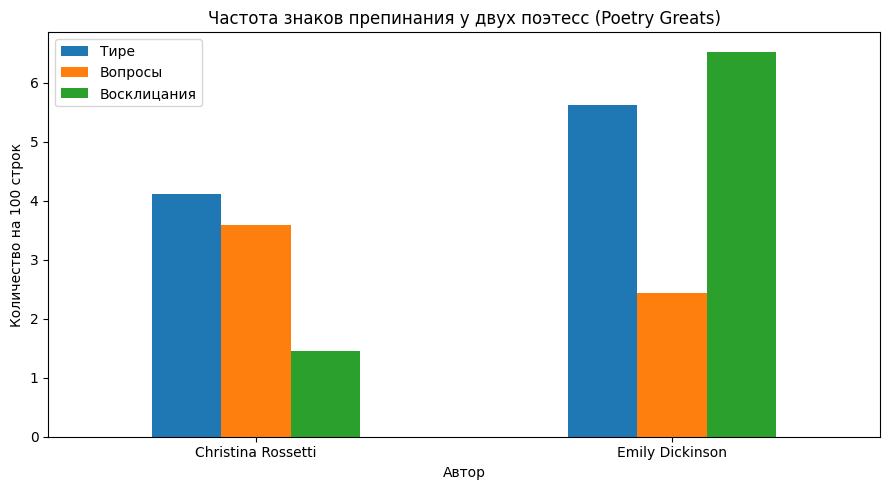

In [68]:
'''График в качестве бонуса'''

columns = [
  "dashes_per_100_lines",
  "questions_per_100_lines",
  "exclamations_per_100_lines"
]

summary_greats[columns].plot(kind="bar", figsize=(9, 5))

plt.title("Частота знаков препинания у двух поэтесс (Poetry Greats)")
plt.ylabel("Количество на 100 строк")
plt.xlabel("Автор")
plt.xticks(rotation=0)
plt.legend(["Тире", "Вопросы", "Восклицания"])
plt.tight_layout()
plt.show()

In [72]:
rossetti_greats = df_greats[df_greats["author"] == "Christina Rossetti"].copy()

rossetti_greats["length_group"] = pd.cut(
  rossetti_greats["linecount"],
  bins=[0, 12, 24, float("inf")],
  labels=["Короткие", "Средние", "Длинные"]
)

length_summary_rossetti = rossetti_greats.groupby("length_group", observed=True).agg(
  poems=("author", "size"),
  total_lines=("linecount", "sum"),
  dashes=("dashes", "sum"),
  questions=("questions", "sum"),
  exclamations=("exclamations", "sum")
)

for mark in ["dashes", "questions", "exclamations"]:
  length_summary_rossetti[mark + "_per_100_lines"] = (length_summary_rossetti[mark] / length_summary_rossetti["total_lines"] * 100).round(2)

length_summary_rossetti

,poems,total_lines,dashes,questions,exclamations,dashes_per_100_lines,questions_per_100_lines,exclamations_per_100_lines
length_group,,,,,,,,
Короткие,110,761,45,20,13,5.91,2.63,1.71
Средние,194,3211,140,162,67,4.36,5.05,2.09
Длинные,155,10911,426,353,136,3.90,3.24,1.25
